In [32]:
%env CUDA_VISIBLE_DEVICES=1
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
import os
import torch

env: CUDA_VISIBLE_DEVICES=1
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [33]:
import cne

In [70]:
# first dataset: circle with noise
n = 400
theta = np.linspace(0, 2 * np.pi, n)
x1 = np.cos(theta) + 0.1 * np.random.randn(n)
x2 = np.sin(theta) + 0.1 * np.random.randn(n)
x = np.stack([x1, x2], axis=1)


# second dataset: square with four sides and noise
n_side = n // 4 //2
x1_side1 = np.linspace(-1, 1, n_side) + 0.1 * np.random.randn(n_side)
x2_side1 = -1 + 0.1 * np.random.randn(n_side)
x1_side2 = 1 + 0.1 * np.random.randn(n_side)
x2_side2 = np.linspace(-1, 1, n_side) + 0.1 * np.random.randn(n_side)
x1_side3 = np.linspace(1, -1, n_side) + 0.1 * np.random.randn(n_side)
x2_side3 = 1 + 0.1 * np.random.randn(n_side)
x1_side4 = -1 + 0.1 * np.random.randn(n_side)
x2_side4 = np.linspace(1, -1, n_side) + 0.1 * np.random.randn(n_side)
x_square = np.concatenate([
    np.stack([x1_side1, x2_side1], axis=1),
    np.stack([x1_side2, x2_side2], axis=1),
    np.stack([x1_side3, x2_side3], axis=1),
    np.stack([x1_side4, x2_side4], axis=1),
], axis=0)

x_square *= 0.3


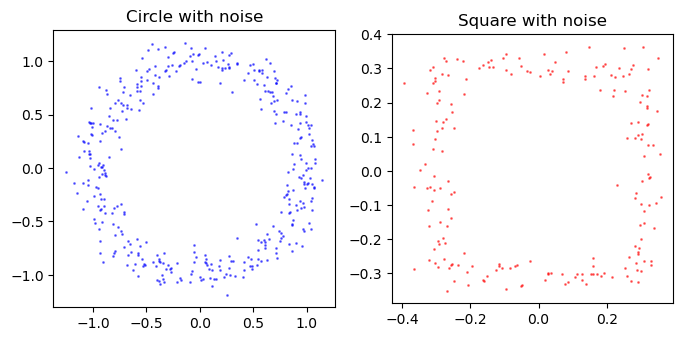

In [71]:
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].scatter(x[:, 0], x[:, 1], s=1.0, color="blue", alpha=0.5)
ax[0].set_title("Circle with noise")
ax[0].set_aspect("equal")
#ax[0].axis("off")
ax[1].scatter(x_square[:, 0], x_square[:, 1], s=1.0, color="red", alpha=0.5)
ax[1].set_title("Square with noise")
ax[1].set_aspect("equal")
#ax[1].axis("off")


In [72]:
# kNNs from other dataset
from sklearn.neighbors import NearestNeighbors
k = 15

nbrs_circle = NearestNeighbors(n_neighbors=k, algorithm='auto').fit(x_square)
_, indices_circle = nbrs_circle.kneighbors(x)

nbrs_square = NearestNeighbors(n_neighbors=k, algorithm='auto').fit(x)
_, indices_square = nbrs_square.kneighbors(x_square)


In [73]:
indices_circle.shape

(400, 15)

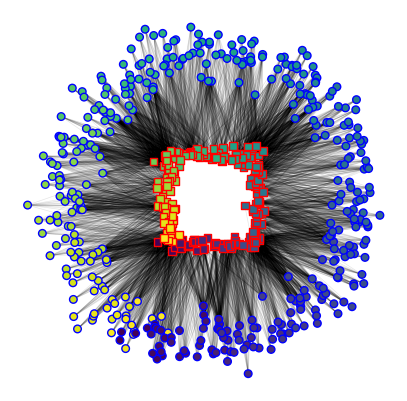

In [105]:
fig, ax = plt.subplots(figsize=(5,5))
ax.scatter(x[:, 0],
           x[:, 1],
           s=30.0,
           facecolors=plt.cm.viridis(((np.arange(len(x)) - len(x)/1.5) % len(x))/len(x)),
           edgecolors="blue",
           linewidth=1,
           marker="o",
           alpha=1,
           zorder=10)
ax.scatter(x_square[:, 0],
           x_square[:, 1],
           s=30.0,
           facecolors=plt.cm.viridis(np.linspace(0, 1, len(x_square))),
           edgecolor="red",
           linewidth=1,
           marker="s",
           alpha=1,
           zorder=10)

for i in range(0, x.shape[0], 1):
    for j in indices_circle[i]:
        ax.plot([x[i, 0], x_square[j, 0]], [x[i, 1], x_square[j, 1]], color="k", alpha=0.1, linewidth=0.5)
for i in range(0, x_square.shape[0], 1):
    for j in indices_square[i]:
        ax.plot([x_square[i, 0], x[j, 0]], [x_square[i, 1], x[j, 1]], color="k", alpha=0.1, linewidth=0.5)
ax.set_aspect("equal")
ax.axis("off")

fig.savefig("alignment_example_data.png", dpi=300)

In [76]:
from scipy.sparse import coo_matrix
rows = np.concatenate([np.arange(x.shape[0]).repeat(k), np.arange(x_square.shape[0]).repeat(k) + x.shape[0]])
cols = np.concatenate([indices_circle.flatten() + x.shape[0], indices_square.flatten()])

graph = coo_matrix((np.ones_like(rows), (rows, cols)), shape=(x.shape[0] + x_square.shape[0], x.shape[0] + x_square.shape[0]))

In [79]:
embedder = cne.CNE(negative_samples=5, batch_size=128, embd_dim=2, n_epochs=400, metric="euclidean", loss_mode="infonce", alignment=True, device="cuda")

In [80]:
data = np.concatenate([x, x_square], axis=0)
embd = embedder.fit_transform(data, graph=graph)

Finished epoch 0/400, loss 116.382
Finished epoch 80/400, loss 94.478
Finished epoch 160/400, loss 90.377
Finished epoch 240/400, loss 87.918
Finished epoch 320/400, loss 86.379


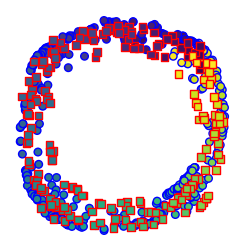

In [107]:
fig, ax = plt.subplots(figsize=(3,3))
ax.scatter(*embd[:x.shape[0]].T,
           s=30.0,
           facecolors=plt.cm.viridis(((np.arange(len(x)) - len(x)/1.5) % len(x))/len(x)),
           edgecolors="blue",
           linewidth=1,
           marker="o",
           alpha=1,
           zorder=10)
ax.scatter(*embd[-x_square.shape[0]:].T,
           s=30.0,
           facecolors=plt.cm.viridis(np.linspace(0, 1, len(x_square))),
           edgecolor="red",
           linewidth=1,
           marker="s",
           alpha=1,
           zorder=10)
ax.set_aspect("equal")
ax.axis("off")
fig.savefig("alignment_example_embd.png", dpi=300)

In [26]:
embedder.model

Embedding(400, 2)

In [34]:
from cne.cne import make_neighbor_indices

In [37]:
make_neighbor_indices(batch_size=100, negative_samples=5, alignment=True, device="cpu")

torch.Size([200, 5])
torch.Size([200, 1])


tensor([[-100,  138,  156,  154,  105,  155],
        [ -99,  158,  194,  173,  175,  190],
        [ -98,  124,  135,  122,  182,  167],
        ...,
        [  97,   37,   77,   21,   15,   23],
        [  98,   25,   55,   14,   25,   82],
        [  99,   95,   67,   25,   90,   34]])